In [1]:
import sys
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from MoireHomo import MoireHomo
import utilsHomo

#### Create Moiré system

In [2]:
sys = MoireHomo(theta_deg=1.2, psi_deg=-89.6, V=8, w=-8.5, n_shells=8)

### Band structure

[0.04376432 0.        ]
[-0.02188216  0.03790101]
-----
[ 0.02188216 -0.01263367]
[-4.82908050e-18 -2.52673426e-02]


(0.0, 26.0)

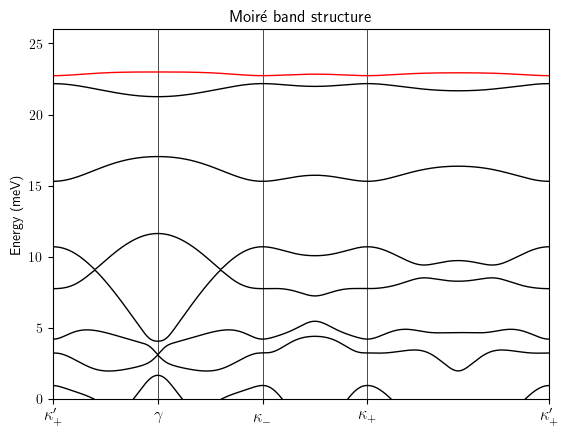

In [3]:
kpath, kdist, ticks = sys.make_k_path(*sys.default_path, n_pts=500)
bands, _ = sys.calculate_bands(kpath=kpath)

print(sys.b1)
print(sys.b2)
print("-----")
print(sys.kappa_plus)
print(sys.kappa_minus)

fig, ax = plt.subplots()
sys.plot_bands(ax, bands, kdist, ticks, max_bands=8)
plt.ylim([0, 26])

### Moiré potential

Text(0.5, 1.0, '$\\Delta(\\mathbf{r})$')

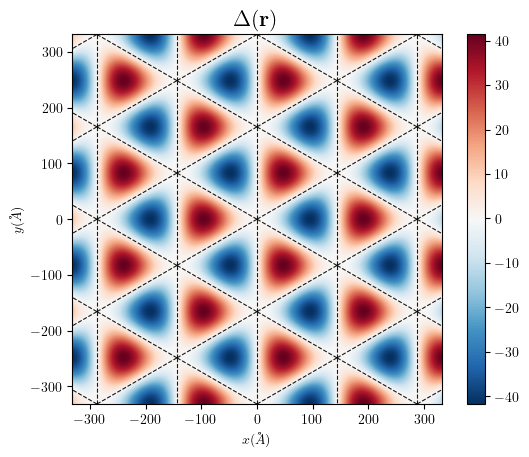

In [4]:
fig, ax = plt.subplots()
scale = 2.0
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
im = sys.plot_moire_potential(ax, extent, resolution=400)
fig.colorbar(im, ax=ax)
sys.plot_triangular_lattice(ax, extent)

ax.set_xlabel(r'$x (\AA)$')
ax.set_ylabel(r'$y (\AA)$')
ax.set_title(r'$\Delta(\mathbf{r})$', fontsize=16)

### Wannier function

Text(0, 0.5, '$y$ (Å)')

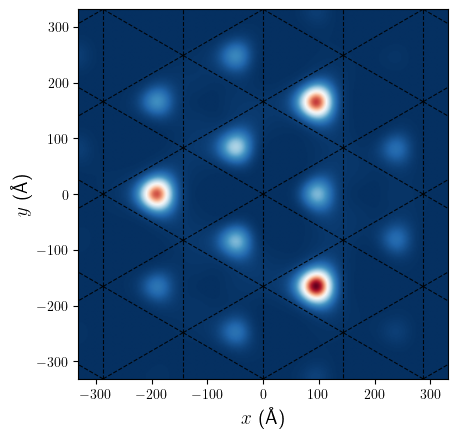

In [5]:
fig, ax = plt.subplots()
k_points = sys.mesh_k_unit_cell()
x = np.linspace(-2 * sys.aM, 2 * sys.aM, 300)
y = np.linspace(-2 * sys.aM, 2 * sys.aM, 300)
X, Y = np.meshgrid(x, y)
sys.plot_wannier_function(ax, X, Y, k_points)
sys.plot_triangular_lattice(ax, extent)

plt.xlabel(r'$x$ (Å)', fontsize=14)
plt.ylabel(r'$y$ (Å)', fontsize=14)

### Berry curvature

Text(0, 0.5, '$k_y$')

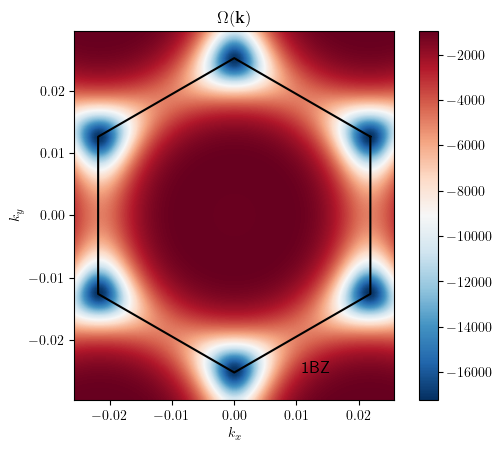

In [6]:
fig, ax = plt.subplots()
scale = 1.2
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 100)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 100)
KX, KY = np.meshgrid(kx, ky)
sys.plot_berry_curvature(ax, KX, KY)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')

In [7]:
berry, KX, KY = sys.berry_curvature(KX, KY)
sys.chern_number_from_grid(berry, KX, KY)

-1.000590677634163

In [8]:
from matplotlib.path import Path as MplPath

In [9]:
phi = np.radians(60)
c, s = np.cos(phi), np.sin(phi)
rot60 = np.array([[c, -s], [s, c]])

corners = np.array([
    sys.kappa_pp,
    sys.kappa_p,
    rot60 @ sys.kappa_p,
    -sys.kappa_pp,
    -sys.kappa_p,
    -(rot60 @ sys.kappa_p),
])

pts = np.vstack([KX.ravel(), KY.ravel()]).T
mask = MplPath(corners).contains_points(pts).reshape(KX.shape)

# grid spacings (assume uniform)
dkx = float(np.abs(KX[0, 1] - KX[0, 0])) if KX.shape[1] > 1 else 1.0
dky = float(np.abs(KY[1, 0] - KY[0, 0])) if KY.shape[0] > 1 else 1.0
dA = dkx * dky

total = np.sum(np.real(berry[mask])) * dA
C = total / (2.0 * np.pi)
print(f"Chern number: {C:.4f}")

Chern number: -1.0006


In [10]:
berry[mask]

array([-16704.39810621, -17035.00677277, -17035.2753059 , ...,
       -14807.52363456, -16995.92419816, -16994.92749027])

In [11]:
berry.shape

(98, 98)

In [12]:
mask

array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]])

### Quantum metric

Text(0, 0.5, '$k_y$')

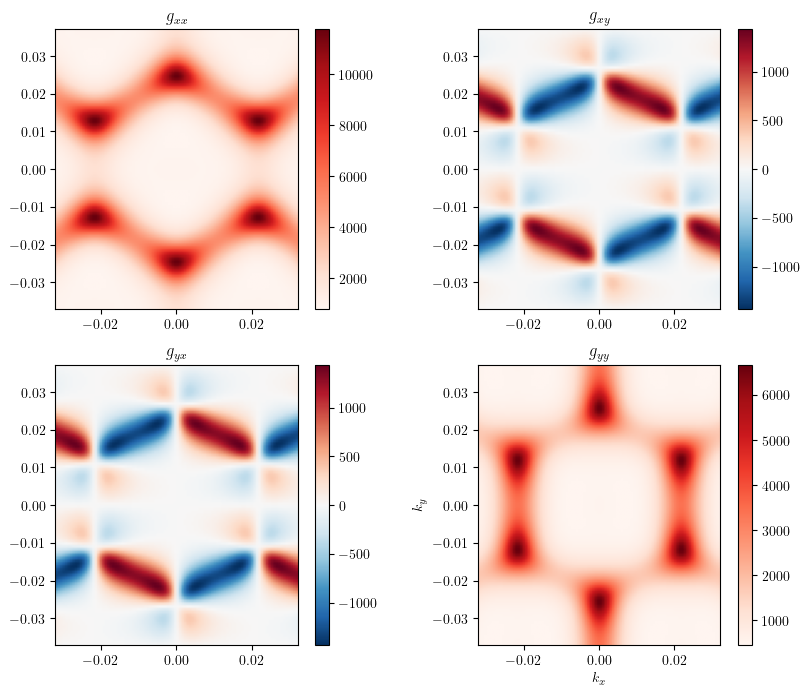

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8))
scale = 1.5
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 100)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 100)
KX, KY = np.meshgrid(kx, ky)
sys.plot_metric(ax, KX, KY)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')

Text(0, 0.5, '$k_y$')

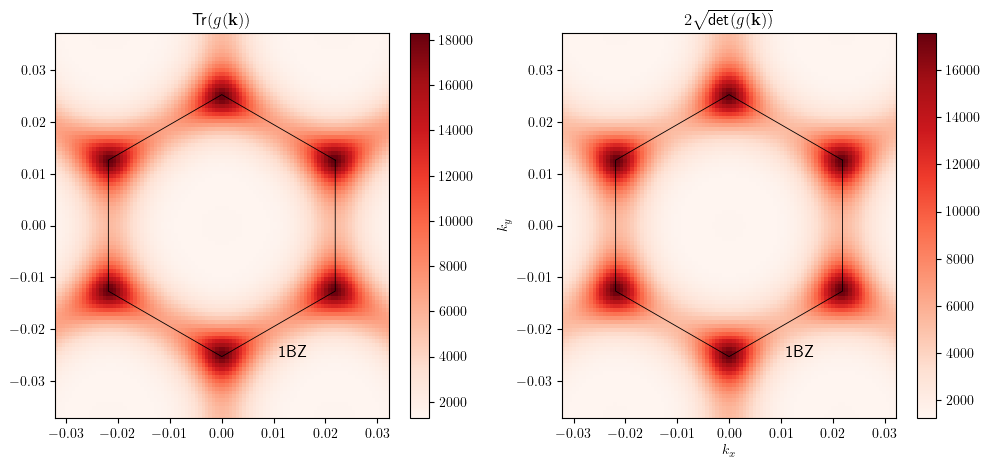

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
scale = 1.5
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 100)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 100)
KX, KY = np.meshgrid(kx, ky)
sys.plot_trace_metric(ax, KX, KY)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')

Text(0, 0.5, '$k_y$')

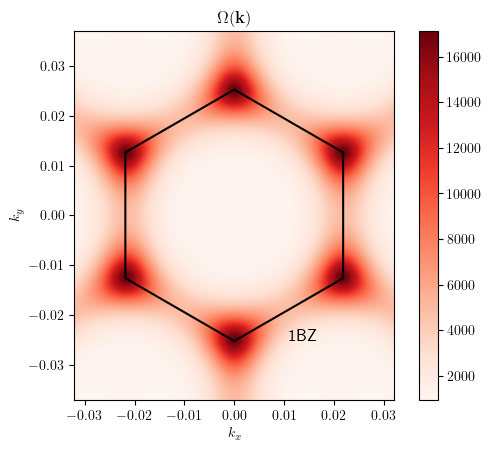

In [15]:
fig, ax = plt.subplots()
scale = 1.5
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 100)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 100)
KX, KY = np.meshgrid(kx, ky)
sys.plot_berry_curvature(ax, KX, KY, abs_val=True)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')